In [1]:

!pip -q install tensorflow scikit-learn seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [2]:

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

# Your dataset uses semicolon-separated columns
df = pd.read_csv(file_name, sep=";")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving Indian Rainfall Dataset District-wise Daily Measurements.csv to Indian Rainfall Dataset District-wise Daily Measurements.csv
Dataset shape: (8790, 34)
Columns: ['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.205834,0.671002,0.028994,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.615237,0.925098,0.507623,0.424843,0.737394,0.0,0.0,0.0


In [3]:

DISTRICT = "Coimbatore"
YEAR = 2022

day_columns = [
    "1st", "2nd", "3rd", "4th", "5th", "6th", "7th",
    "8th", "9th", "10th", "11th", "12th", "13th",
    "14th", "15th", "16th", "17th", "18th", "19th",
    "20th", "21st", "22nd", "23rd", "24th", "25th",
    "26th", "27th", "28th", "29th", "30th", "31st"
]

district_data = df[
    df["district"].astype(str).str.strip().str.lower()
    == DISTRICT.strip().lower()
].copy()

if district_data.empty:
    print("Available districts:")
    print(sorted(df["district"].dropna().unique()))
    raise ValueError("District not found. Change DISTRICT in Cell 3.")

district_data["month"] = pd.to_numeric(
    district_data["month"], errors="coerce"
)

district_data = district_data.sort_values("month")

records = []

for _, row in district_data.iterrows():
    month = int(row["month"])

    for day, col in enumerate(day_columns, start=1):
        try:
            date = pd.Timestamp(YEAR, month, day)
        except ValueError:
            # Skip invalid dates, such as February 30
            continue

        value = pd.to_numeric(row[col], errors="coerce")

        records.append({
            "Date": date,
            "Rainfall": value
        })

daily = pd.DataFrame(records)
daily = daily.sort_values("Date").drop_duplicates("Date")
daily = daily.set_index("Date").asfreq("D")

# Convert invalid values to missing and fill missing rainfall values
daily["Rainfall"] = pd.to_numeric(
    daily["Rainfall"], errors="coerce"
)
daily["Rainfall"] = daily["Rainfall"].replace(
    [np.inf, -np.inf], np.nan
)
daily["Rainfall"] = daily["Rainfall"].clip(lower=0)

# Interpolate only internal missing days, then fill remaining gaps
daily["Rainfall"] = daily["Rainfall"].interpolate(
    method="linear", limit_area="inside"
)
daily["Rainfall"] = daily["Rainfall"].fillna(0)

print("Selected district:", DISTRICT)
print("Number of daily records:", len(daily))
print("Date range:", daily.index.min(), "to", daily.index.max())
display(daily.head())
display(daily.describe())


Selected district: Coimbatore
Number of daily records: 365
Date range: 2022-01-01 00:00:00 to 2022-12-31 00:00:00


,Rainfall
Date,
2022-01-01,2.148890
2022-01-02,9.110140
2022-01-03,0.046436
2022-01-04,0.000000
2022-01-05,0.000000


,Rainfall
count,365.000000
mean,4.087979
std,6.860978
min,0.000000
25%,0.000000
50%,0.458574
75%,5.624350
max,49.671200


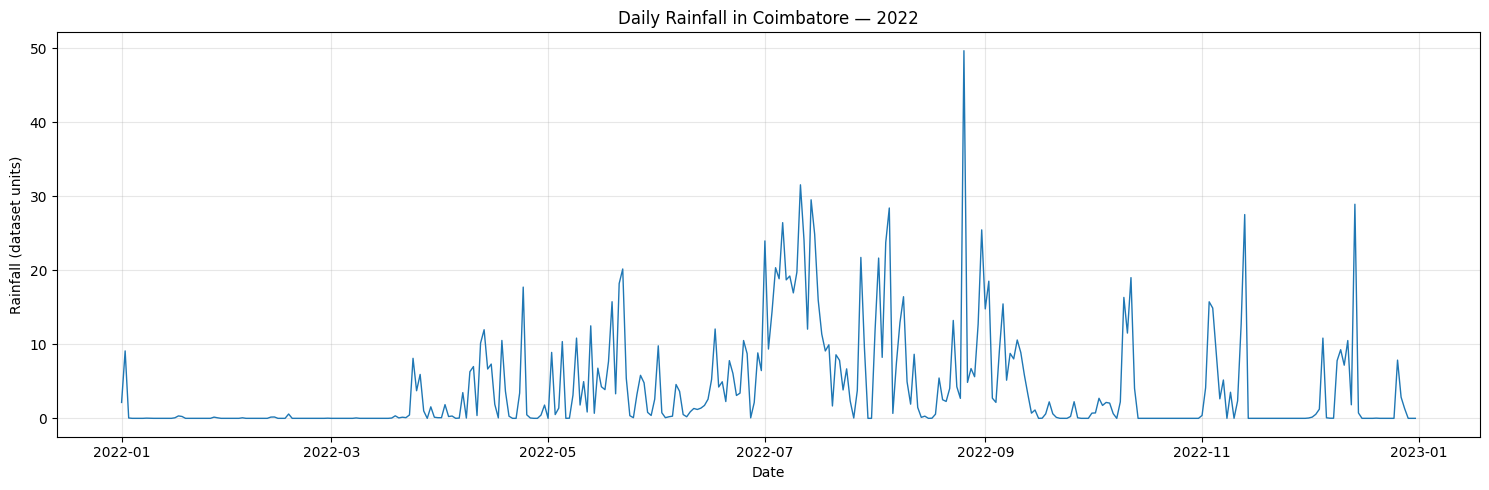

In [4]:

plt.figure(figsize=(15, 5))
plt.plot(daily.index, daily["Rainfall"], linewidth=1)
plt.title(f"Daily Rainfall in {DISTRICT} — {YEAR}")
plt.xlabel("Date")
plt.ylabel("Rainfall (dataset units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:

values = daily["Rainfall"].values.astype("float32").reshape(-1, 1)

# Chronological split: 70% train, 15% validation, 15% test
n = len(values)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

LOOKBACK = 14

if train_end <= LOOKBACK or val_end >= n:
    raise ValueError("Not enough daily data for the selected split.")

scaler = MinMaxScaler()
scaler.fit(values[:train_end])

scaled_values = scaler.transform(values)

def create_sequences(data, lookback):
    X, y, target_indices = [], [], []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])
        target_indices.append(i)

    return (
        np.array(X, dtype=np.float32).reshape(-1, lookback, 1),
        np.array(y, dtype=np.float32),
        np.array(target_indices)
    )

X_all, y_all, target_indices = create_sequences(
    scaled_values, LOOKBACK
)

train_mask = target_indices < train_end
val_mask = (
    (target_indices >= train_end)
    & (target_indices < val_end)
)
test_mask = target_indices >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

print("X_train:", X_train.shape, y_train.shape)
print("X_val:  ", X_val.shape, y_val.shape)
print("X_test: ", X_test.shape, y_test.shape)


X_train: (241, 14, 1) (241,)
X_val:   (55, 14, 1) (55,)
X_test:  (55, 14, 1) (55,)


In [6]:

model = Sequential([
    tf.keras.Input(shape=(LOOKBACK, 1)),

    LSTM(32, return_sequences=True),
    Dropout(0.2),

    LSTM(16),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 14, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,777 (30.38 KB)

 Trainable params: 7,777 (30.38 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    shuffle=False,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


Epoch 1/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.0235 - mae: 0.0826 - val_loss: 0.0100 - val_mae: 0.0836 - learning_rate: 0.0010
Epoch 2/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0188 - mae: 0.0971 - val_loss: 0.0129 - val_mae: 0.1038 - learning_rate: 0.0010
Epoch 3/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0189 - mae: 0.1016 - val_loss: 0.0112 - val_mae: 0.0901 - learning_rate: 0.0010
Epoch 4/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0176 - mae: 0.0935 - val_loss: 0.0112 - val_mae: 0.0857 - learning_rate: 0.0010
Epoch 5/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0170 - mae: 0.0909 - val_loss: 0.0109 - val_mae: 0.0796 - learning_rate: 0.0010
Epoch 6/150
11/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0036 - mae: 0.0477
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0159 - mae: 0.0829 - val_loss: 0.0110 - val_mae: 0.0803 - learning_rate: 0.0010
Epo

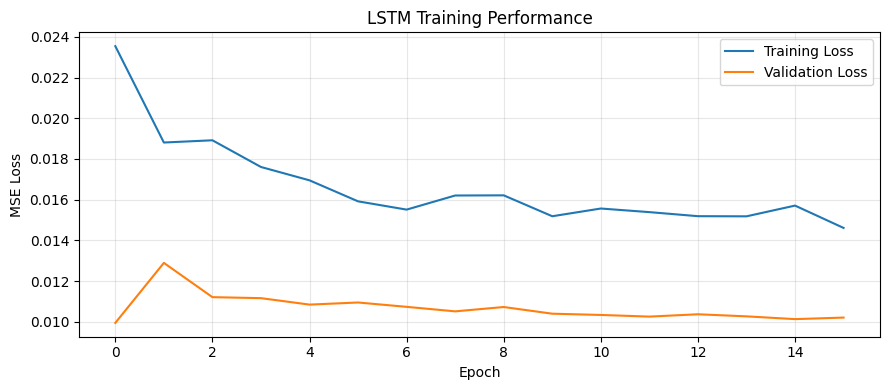

In [8]:

plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training Performance")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:

pred_scaled = model.predict(X_test, verbose=0)

y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

# Rainfall cannot be negative
y_pred = np.maximum(y_pred, 0)

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("DISTRICT:", DISTRICT)
print(f"Test MAE:  {mae:.4f} rainfall units")
print(f"Test RMSE: {rmse:.4f} rainfall units")


DISTRICT: Coimbatore
Test MAE:  4.7472 rainfall units
Test RMSE: 6.1422 rainfall units


Rain/No-Rain Accuracy: 34.55%
Precision: 34.55%
Recall:    100.00%
F1-score:  51.35%

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.00      0.00      0.00        36
        Rain       0.35      1.00      0.51        19

    accuracy                           0.35        55
   macro avg       0.17      0.50      0.26        55
weighted avg       0.12      0.35      0.18        55



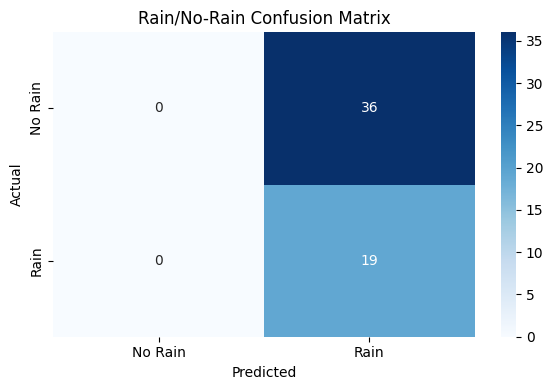

In [10]:

RAIN_THRESHOLD = 0.1

actual_class = (y_actual >= RAIN_THRESHOLD).astype(int)
predicted_class = (y_pred >= RAIN_THRESHOLD).astype(int)

accuracy = accuracy_score(actual_class, predicted_class)
precision = precision_score(
    actual_class, predicted_class, zero_division=0
)
recall = recall_score(
    actual_class, predicted_class, zero_division=0
)
f1 = f1_score(
    actual_class, predicted_class, zero_division=0
)

print(f"Rain/No-Rain Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-score:  {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    actual_class,
    predicted_class,
    labels=[0, 1],
    target_names=["No Rain", "Rain"],
    zero_division=0
))

cm = confusion_matrix(actual_class, predicted_class, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Rain/No-Rain Confusion Matrix")
plt.tight_layout()
plt.show()


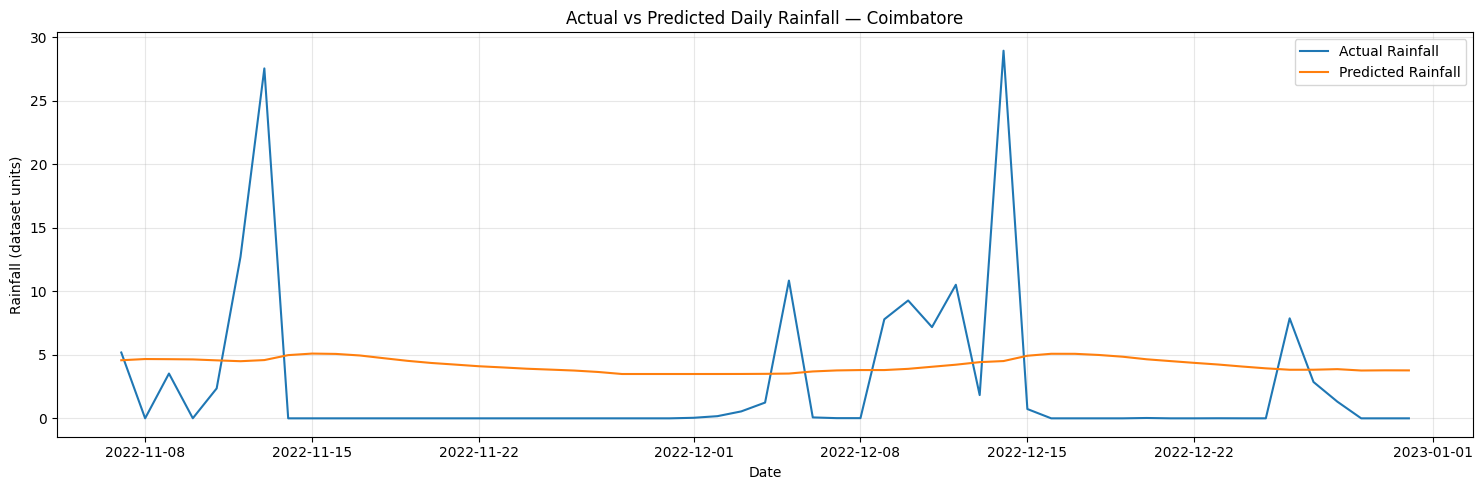

In [11]:

test_dates = daily.index[target_indices[test_mask]]

plt.figure(figsize=(15, 5))
plt.plot(test_dates, y_actual, label="Actual Rainfall", linewidth=1.5)
plt.plot(test_dates, y_pred, label="Predicted Rainfall", linewidth=1.5)

plt.title(f"Actual vs Predicted Daily Rainfall — {DISTRICT}")
plt.xlabel("Date")
plt.ylabel("Rainfall (dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Rainfall": y_actual,
    "Predicted_Rainfall": y_pred
})

results["Absolute_Error"] = abs(
    results["Actual_Rainfall"] - results["Predicted_Rainfall"]
)

display(results.head(20))


,Date,Actual_Rainfall,Predicted_Rainfall,Absolute_Error
0,2022-11-07,5.180290,4.571505,0.608785
1,2022-11-08,0.001687,4.666537,4.664851
2,2022-11-09,3.525730,4.655225,1.129495
3,2022-11-10,0.005991,4.636890,4.630899
4,2022-11-11,2.355210,4.562924,2.207714
5,2022-11-12,12.711200,4.495338,8.215861
6,2022-11-13,27.534002,4.584308,22.949696
7,2022-11-14,0.000000,4.974378,4.974378
8,2022-11-15,0.000000,5.095941,5.095941
9,2022-11-16,0.000000,5.069750,5.069750


In [13]:

last_sequence = scaled_values[-LOOKBACK:].reshape(
    1, LOOKBACK, 1
)

next_scaled = model.predict(last_sequence, verbose=0)

next_rainfall = scaler.inverse_transform(
    next_scaled.reshape(-1, 1)
)[0, 0]

next_rainfall = max(0.0, float(next_rainfall))
next_date = daily.index[-1] + pd.Timedelta(days=1)

print("District:", DISTRICT)
print("Prediction date:", next_date.date())
print(f"Predicted rainfall: {next_rainfall:.4f} dataset units")
print(
    "Predicted category:",
    "Rain" if next_rainfall >= RAIN_THRESHOLD else "No Rain"
)


District: Coimbatore
Prediction date: 2023-01-01
Predicted rainfall: 3.7547 dataset units
Predicted category: Rain


In [14]:

LOOKBACK = 30
RAIN_THRESHOLD = 0.1

rainfall = daily["Rainfall"].values.astype("float32")
n = len(rainfall)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Scale using training data only
scaler_cls = MinMaxScaler()
scaler_cls.fit(rainfall[:train_end].reshape(-1, 1))

scaled = scaler_cls.transform(
    rainfall.reshape(-1, 1)
).ravel()

# 1 = Rain, 0 = No Rain
labels = (rainfall >= RAIN_THRESHOLD).astype("float32")

X, y, target_idx = [], [], []

for i in range(LOOKBACK, n):
    X.append(scaled[i-LOOKBACK:i])
    y.append(labels[i])
    target_idx.append(i)

X = np.array(X, dtype="float32").reshape(-1, LOOKBACK, 1)
y = np.array(y, dtype="float32")
target_idx = np.array(target_idx)

tr = target_idx < train_end
va = (target_idx >= train_end) & (target_idx < val_end)
te = target_idx >= val_end

X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]

print("Train:", X_train.shape, "Rain rate:", round(float(y_train.mean()), 3))
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (225, 30, 1) Rain rate: 0.693
Validation: (55, 30, 1)
Test: (55, 30, 1)


In [15]:

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train.astype(int))
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.astype(int)
)
class_weights = dict(zip(classes, weights))

classifier = Sequential([
    tf.keras.Input(shape=(LOOKBACK, 1)),
    LSTM(32, return_sequences=True),
    Dropout(0.2),
    LSTM(16),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

classifier.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        patience=4,
        factor=0.5,
        min_lr=0.00001
    )
]

history_cls = classifier.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    shuffle=False,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - accuracy: 0.2933 - loss: 0.6997 - val_accuracy: 0.5091 - val_loss: 0.6941 - learning_rate: 0.0010
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5244 - loss: 0.6836 - val_accuracy: 0.4545 - val_loss: 0.6960 - learning_rate: 0.0010
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6667 - loss: 0.6580 - val_accuracy: 0.3455 - val_loss: 0.7024 - learning_rate: 0.0010
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8044 - loss: 0.5900 - val_accuracy: 0.5273 - val_loss: 0.7608 - learning_rate: 0.0010
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7956 - loss: 0.5120 - val_accuracy: 0.6727 - val_loss: 0.7345 - learning_rate: 0.0010
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8178 - loss: 0.4781 - val_accuracy: 0.7091 - val_loss: 0.6882 - learning_rate: 5.0000e-04
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8089 - loss: 0.454

In [16]:

val_prob = classifier.predict(X_val, verbose=0).ravel()

# Select threshold that maximizes validation accuracy.
# Test labels are not used for threshold selection.
thresholds = np.arange(0.10, 0.91, 0.02)

scores = [
    accuracy_score(y_val.astype(int), (val_prob >= t).astype(int))
    for t in thresholds
]

best_threshold = float(thresholds[np.argmax(scores)])

print(f"Selected threshold: {best_threshold:.2f}")
print(f"Validation accuracy: {max(scores) * 100:.2f}%")


Selected threshold: 0.78
Validation accuracy: 76.36%


Test Accuracy:  58.18%
Precision:      41.67%
Recall:         52.63%
F1-score:       46.51%

               precision    recall  f1-score   support

     No Rain       0.71      0.61      0.66        36
        Rain       0.42      0.53      0.47        19

    accuracy                           0.58        55
   macro avg       0.56      0.57      0.56        55
weighted avg       0.61      0.58      0.59        55



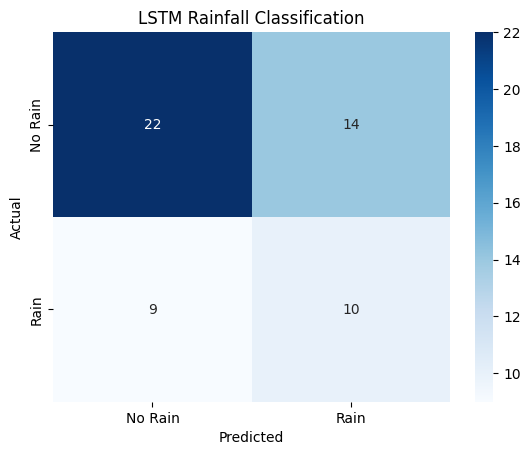

Majority baseline accuracy: 34.55%


In [17]:

test_prob = classifier.predict(X_test, verbose=0).ravel()

y_true = y_test.astype(int)
y_pred_class = (test_prob >= best_threshold).astype(int)

print(f"Test Accuracy:  {accuracy_score(y_true, y_pred_class)*100:.2f}%")
print(f"Precision:      {precision_score(y_true, y_pred_class, zero_division=0)*100:.2f}%")
print(f"Recall:         {recall_score(y_true, y_pred_class, zero_division=0)*100:.2f}%")
print(f"F1-score:       {f1_score(y_true, y_pred_class, zero_division=0)*100:.2f}%")

print("\n", classification_report(
    y_true, y_pred_class,
    labels=[0, 1],
    target_names=["No Rain", "Rain"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred_class, labels=[0, 1])

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LSTM Rainfall Classification")
plt.show()

# Compare with a simple majority-class baseline
baseline = np.full_like(y_true, int(y_train.mean() >= 0.5))
print(
    f"Majority baseline accuracy: "
    f"{accuracy_score(y_true, baseline)*100:.2f}%"
)


In [18]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# y_actual and y_pred must be rainfall values in original units (mm)
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"MAE  : {mae:.4f} mm")
print(f"RMSE : {rmse:.4f} mm")


MAE  : 4.7472 mm
RMSE : 6.1422 mm
